In [1]:
from IPython import display
import ultralytics

In [2]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
import cv2
import matplotlib.pyplot as plt

In [4]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.174  Python-3.13.15 torch-2.14.1+cpu CPU (Intel Core i5-14500)
Setup complete  (20 CPUs, 31.7 GB RAM, 64.4/1862.9 GB disk)


In [5]:
model = ultralytics.YOLO("yolo26n-seg.yaml").load("yolo26n-seg.pt")

Transferred 844/844 items from pretrained weights


In [6]:
img = "dataset/data/31b8c691-1b4b8bf7-009b71cc4fd38230.jpg"
result = model.predict(img)


image 1/1 d:\ml_s2\projectyolo\dataset\data\31b8c691-1b4b8bf7-009b71cc4fd38230.jpg: 608x640 1 16, 1 57, 142.1ms
Speed: 5.3ms preprocess, 142.1ms inference, 5.6ms postprocess per image at shape (1, 3, 608, 640)


mask =  2
x =  [[  19    4]
 [  19  592]
 [  20  593]
 [  20  598]
 [  22  600]
 [  22  601]
 [  28  608]
 [  28  609]
 [  32  612]
 [  32  624]
 [  28  627]
 [  25  624]
 [  22  624]
 [  20  622]
 [  19  622]
 [  19  771]
 [  20  772]
 [  20  774]
 [  25  779]
 [  25  780]
 [  32  787]
 [  32  788]
 [  33  790]
 [  33  792]
 [  35  793]
 [  36  793]
 [  41  798]
 [  43  798]
 [  44  796]
 [  46  796]
 [  48  795]
 [  52  795]
 [  56  798]
 [  56  800]
 [  59  803]
 [  59  804]
 [  60  806]
 [  62  806]
 [  65  809]
 [  65  811]
 [  67  811]
 [  70  814]
 [  70  816]
 [  72  817]
 [  72  819]
 [  73  820]
 [  73  822]
 [  76  825]
 [  78  825]
 [  83  830]
 [  83  832]
 [  84  833]
 [  84  836]
 [  86  838]
 [  88  838]
 [  91  841]
 [  92  841]
 [  94  843]
 [  94  844]
 [  97  848]
 [  97  849]
 [  99  851]
 [ 100  851]
 [ 102  852]
 [ 105  852]
 [ 107  854]
 [ 108  854]
 [ 112  857]
 [ 112  862]
 [ 115  862]
 [ 116  864]
 [ 118  864]
 [ 124  870]
 [ 126  870]
 [ 128  872]
 [ 128  87

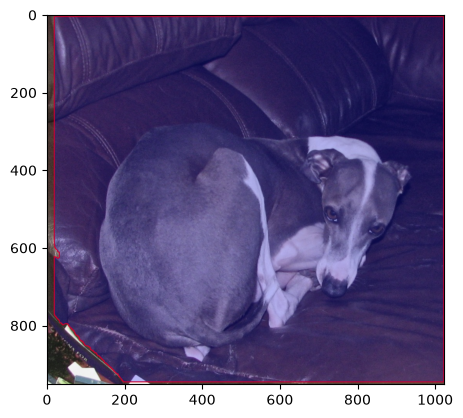

In [7]:
# print(result[0])
# print(len(result[0].boxes))
myimage = cv2.imread(img)
overlay = myimage.copy()
myimage = cv2.cvtColor(myimage, cv2.COLOR_BGR2RGB)
# plt.imshow(myimage)

# for box in result[0].boxes:
#     print(box)
#     class_id = result[0].names[box.cls[0].item()]
#     print(class_id)
#     coor = box.xyxy[0].tolist()
#     coors = [round(x) for x in coor]
#     print(coors)
#     cf = round(box.conf[0].item(), 2)
#     print(cf)
#     myimage = cv2.rectangle(myimage, (coors[0], coors[1]), (coors[2], coors[3]), (255,0,0))

print("mask = ", len(result[0].masks))
for idx in range(len(result[0].masks)):
    # print(mask)
    x = result[0].masks.xy[idx].astype(int)
    pts = x.reshape((-1, 1, 2))
    myimage = cv2.polylines(myimage, [pts], isClosed=True, color=(255, 0, 0), thickness=2)
    overlay = cv2.fillPoly(overlay, pts=[pts], color=(0, 0, 255))
    print("x = ", x)
    break
alpha = 0.25
myimage = cv2.addWeighted(overlay, alpha, myimage, 1 - alpha, 0)

plt.imshow(myimage)